In [2]:
import sys
from pathlib import Path

# Permitir importaciones desde la raíz del proyecto
directorio_raiz = Path("..").resolve()
if str(directorio_raiz) not in sys.path:
    sys.path.append(str(directorio_raiz))

# Importar funciones desde sus respectivos módulos
from src.analisis_datos.estadistico import (
    calcular_estadisticos_cuantitativos,
    imprimir_resumen_cuantitativo,
)
from src.analisis_datos.ingesta import cargar_datos_raw

# 1. Cargar datos (el módulo ingesta ya sabe la ruta automáticamente)
df_steel = cargar_datos_raw()

# 2. Definir variables
vars_cuantitativas = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
]

# 3. Calcular estadísticos
df_resumen = calcular_estadisticos_cuantitativos(df_steel, vars_cuantitativas)

# 4. Desplegar resultados
display(df_resumen)

[✓] Cargas exitosa desde: data/raw/Steel_industry_data.csv


,Variable,Media,Mediana,Desv. Est.,Mínimo,Máximo,IQR,Asimetría (Skew),Curtosis (Kurt)
0,Usage_kWh,27.39,4.57,33.44,0.0,157.18,48.04,1.20,0.39
1,Lagging_Current_Reactive.Power_kVarh,13.04,5.00,16.31,0.0,96.91,20.34,1.44,1.21
2,Leading_Current_Reactive_Power_kVarh,3.87,0.00,7.42,0.0,27.76,2.09,1.73,1.58
3,CO2(tCO2),0.01,0.00,0.02,0.0,0.07,0.02,1.15,0.21
4,Lagging_Current_Power_Factor,80.58,87.96,18.92,0.0,100.00,35.70,-0.61,-1.10
5,Leading_Current_Power_Factor,84.37,100.00,30.46,0.0,100.00,0.30,-1.51,0.38
6,NSM,42750.00,42750.00,24940.53,0.0,85500.00,42750.00,0.00,-1.20


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[✓] Cargas exitosa desde: data/raw/Steel_industry_data.csv


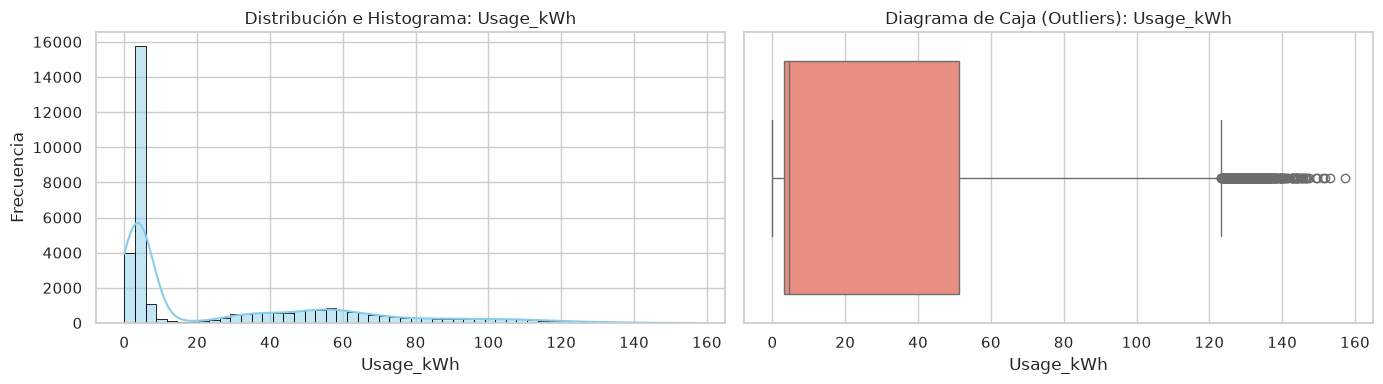

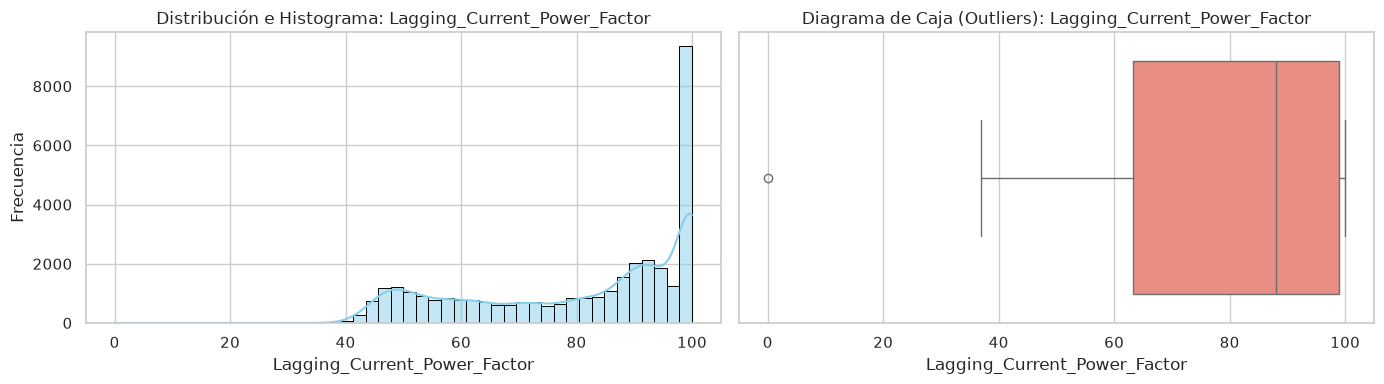

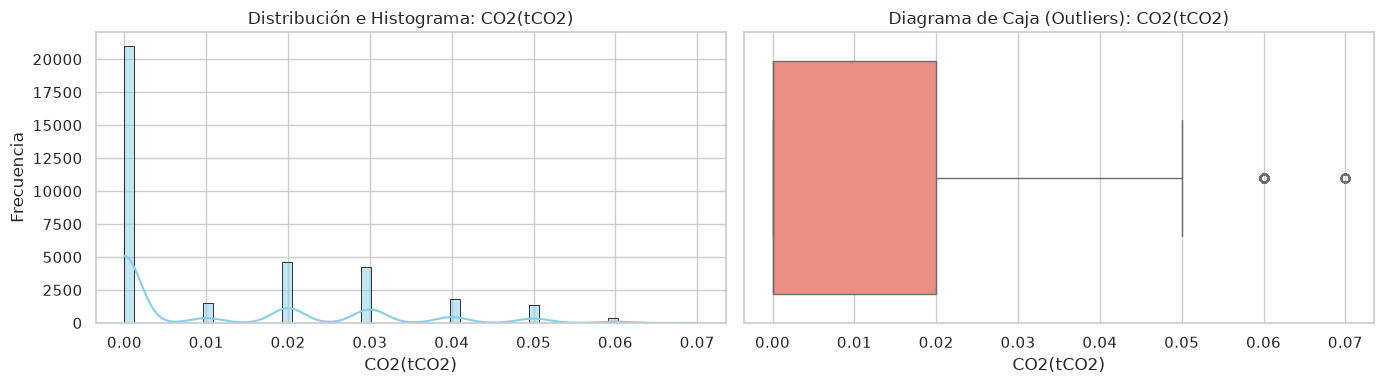

In [5]:
import sys
from pathlib import Path

# 1. Configurar la ruta raíz del proyecto
directorio_raiz = Path("..").resolve()
if str(directorio_raiz) not in sys.path:
    sys.path.append(str(directorio_raiz))

# 2. Activar recarga automática de módulos
%load_ext autoreload
%autoreload 2

# 3. Importaciones sin sangría inicial
from src.analisis_datos.graficos import graficar_distribucion_y_boxplots
from src.analisis_datos.ingesta import cargar_datos_raw

# 4. Cargar el dataset
df_steel = cargar_datos_raw()

# 5. Definir variables y generar gráficos
vars_interes = ["Usage_kWh", "Lagging_Current_Power_Factor", "CO2(tCO2)"]
graficar_distribucion_y_boxplots(df_steel, vars_interes)

In [9]:
from src.analisis_datos.ingesta import cargar_datos_raw
from src.analisis_datos.categoricas import calcular_frecuencias_categoricas

# 1. Cargar el dataset
df_steel = cargar_datos_raw()

# 2. Llamar a la función del módulo .py
tablas_cat = calcular_frecuencias_categoricas(df_steel)

# 3. Mostrar los resultados
for nombre_var, df_tabla in tablas_cat.items():
    print(f"=== Tabla de Frecuencias: {nombre_var} ===")
    display(df_tabla)
    print("\n")

[✓] Cargas exitosa desde: data/raw/Steel_industry_data.csv
=== Tabla de Frecuencias: WeekStatus ===


,Frecuencia Absoluta (N°),Proporción Relativa (%)
WeekStatus,,
Weekday,25056,71.51%
Weekend,9984,28.49%




=== Tabla de Frecuencias: Day_of_week ===


,Frecuencia Absoluta (N°),Proporción Relativa (%)
Day_of_week,,
Monday,5088,14.52%
Tuesday,4992,14.25%
Wednesday,4992,14.25%
Thursday,4992,14.25%
Friday,4992,14.25%
Saturday,4992,14.25%
Sunday,4992,14.25%




=== Tabla de Frecuencias: Load_Type ===


,Frecuencia Absoluta (N°),Proporción Relativa (%)
Load_Type,,
Light_Load,18072,51.58%
Medium_Load,9696,27.67%
Maximum_Load,7272,20.75%
